In [1]:
!nvidia-smi

Tue Nov 10 06:46:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
DATASET_PATH = '/kaggle/working/'
import os

In [3]:
import json, random
import torch , torch.nn as nn , torch.nn.functional as F , torchvision
from torch.utils.data import DataLoader
from torchvision import transforms , datasets, models
import numpy as np
import matplotlib.pyplot as plt

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
use_amp = device == 'cuda'
print(device)

cuda


In [5]:
BATCH_SIZE = 256
BATCH_SIZE_VIT_TEACHER = 64
IMG_SIZE = 32
PATCH_SIZE = 4
ATTENTION_HEADS = 4
TRANSFORMER_LAYER = 6
EMBED_DIM = 128
CLASSES = 100
EPOCHS_TEACHER_RESNET = 8
EPOCHS_TEACHER_VIT = 8
LR_TEACHER_RESNET = 1e-4
LR_TEACHER_VIT = 3e-5
EPOCHS_STUDENT = 60
LR_STUDENT = 5e-4
WEIGHT_DECAY = 0.05
CHANNELS = 3
TEMPERATURE = 2
ALPHA = 0.5
TEACHER_IMG_RES = 64
TEACHER_IMG_VIT = 224

In [6]:
mean, std = (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)

train_transformations = transforms.Compose([transforms.RandomCrop(32, padding=4),
                                            transforms.RandomHorizontalFlip(),
                                            transforms.ToTensor(),
                                            transforms.Normalize(mean, std)])
val_transformations = transforms.Compose([transforms.ToTensor(),
                                          transforms.Normalize(mean, std)])

train_dataset = datasets.CIFAR100(root=DATASET_PATH,train=True, download=True, transform= train_transformations)
val_dataset = datasets.CIFAR100(root=DATASET_PATH,train=False, download=True,  transform= val_transformations)

100%|██████████| 169M/169M [19:49<00:00, 142kB/s]


In [7]:
train_dataloader = DataLoader(train_dataset,batch_size= BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
train_dataloader_vit = DataLoader(train_dataset,batch_size= BATCH_SIZE_VIT_TEACHER, shuffle=True, num_workers=2, pin_memory=True)
val_dataloader = DataLoader(val_dataset,batch_size= BATCH_SIZE, num_workers=2, pin_memory=True)

In [8]:
cifar_mean = torch.tensor(mean, device=device).view(1,3,1,1)
cifar_std = torch.tensor(std, device=device).view(1,3,1,1)
imagenet_mean = torch.tensor((0.485, 0.456, 0.406), device=device).view(1,3,1,1)
imagenet_std = torch.tensor((0.229, 0.224, 0.225), device=device).view(1,3,1,1)
scale = cifar_std / imagenet_std
shift = (cifar_mean - imagenet_mean) / imagenet_std

def to_imagenet(x):
  return x * scale + shift

def autocast_ctx():
  return torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp)

def set_seed(seed=0):
  random.seed(seed); np.random.seed(seed)
  torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def freeze(model):
  model.eval()
  for p in model.parameters(): p.requires_grad = False

In [9]:
teacher_resnet = models.resnet50(weights= models.ResNet50_Weights.IMAGENET1K_V2)
teacher_resnet.fc = nn.Linear(teacher_resnet.fc.in_features,CLASSES)
teacher_resnet = teacher_resnet.to(device)

def resnet_forward(x):
  x = F.interpolate(to_imagenet(x), size=TEACHER_IMG_RES, mode='bilinear', align_corners=False)
  return teacher_resnet(x)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 259MB/s]


In [10]:
teacher_vit = models.vit_b_16(weights= models.ViT_B_16_Weights.IMAGENET1K_V1)
teacher_vit.heads.head = nn.Linear(teacher_vit.heads.head.in_features,CLASSES)
teacher_vit = teacher_vit.to(device)

def vit_forward(x):
  x = F.interpolate(to_imagenet(x), size=TEACHER_IMG_VIT, mode='bilinear', align_corners=False)
  return teacher_vit(x)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 255MB/s]


In [11]:
class PatchEmbed(nn.Module):
  def __init__(self,num_channels= CHANNELS, embed_dim=EMBED_DIM, patch_size= PATCH_SIZE,img_size = IMG_SIZE):
    super().__init__()
    self.proj = nn.Conv2d(num_channels ,embed_dim ,patch_size , patch_size)
    self.n = (img_size // patch_size) ** 2

  def forward(self,x):
    x = self.proj(x)
    x = x.flatten(2)
    x = x.transpose(1,2)
    return x

class ViT(nn.Module):
  def __init__(self,embed_dim= EMBED_DIM, attention_heads= ATTENTION_HEADS, layers= TRANSFORMER_LAYER,classes = CLASSES, distill=True):
    super().__init__()
    self.distill = distill
    self.patch_embed = PatchEmbed()
    self.cls = nn.Parameter(torch.zeros(1,1,embed_dim))
    n = self.patch_embed.n
    if distill:
      self.distillation = nn.Parameter(torch.zeros(1,1,embed_dim))
      self.head_distil = nn.Linear(embed_dim, classes)
      self.position = nn.Parameter(torch.zeros(1,n+2,embed_dim))
    else:
      self.position = nn.Parameter(torch.zeros(1,n+1,embed_dim))
    self.transformer_block = nn.Sequential(*[nn.TransformerEncoderLayer(embed_dim,attention_heads,4*embed_dim , batch_first=True) for _ in range(layers)])
    self.layernorm = nn.LayerNorm(embed_dim)
    self.head_cls = nn.Linear(embed_dim, classes)

  def forward(self,x):
    B = x.shape[0]
    x = self.patch_embed(x)
    cls = self.cls.expand(B,-1,-1)
    if self.distill:
      dist = self.distillation.expand(B,-1,-1)
      x = torch.cat([cls,x,dist],1) + self.position
    else:
      x = torch.cat([cls,x],1) + self.position
    x = self.transformer_block(x)
    x = self.layernorm(x)
    cls_logits = self.head_cls(x[:,0])
    if not self.distill:
      return cls_logits, None
    dist_logits = self.head_distil(x[:,-1])
    return cls_logits, dist_logits

In [12]:
def kd_loss(cls_logits, distil_logits, t_logits, y, alpha=ALPHA, temperature = TEMPERATURE):
  kd = F.kl_div(F.log_softmax(distil_logits/temperature, dim=1),
                F.softmax(t_logits/temperature, dim=1),
                reduction = 'batchmean') * (temperature**2)
  ce = F.cross_entropy(cls_logits, y)
  return alpha * kd + (1-alpha) * ce

In [13]:
def evaluate_teacher(forward_fn, model):
  model.eval()
  correct=0; total=0
  with torch.no_grad(), autocast_ctx():
    for x,y in val_dataloader:
      x,y = x.to(device), y.to(device)
      correct += (forward_fn(x).argmax(1)==y).sum().item(); total += y.size(0)
  return 100 * correct/total

def evaluate_student(model):
  model.eval()
  c_cls=0; c_dist=0; c_avg=0; total=0
  with torch.no_grad(), autocast_ctx():
    for x,y in val_dataloader:
      x,y = x.to(device), y.to(device)
      cls_logits, dist_logits = model(x)
      c_cls += (cls_logits.argmax(1)==y).sum().item()
      if dist_logits is not None:
        c_dist += (dist_logits.argmax(1)==y).sum().item()
        c_avg += (((cls_logits.float()+dist_logits.float())/2).argmax(1)==y).sum().item()
      total += y.size(0)
  out = {'cls': 100*c_cls/total}
  if model.distill:
    out['dist'] = 100*c_dist/total
    out['avg'] = 100*c_avg/total
  return out

In [14]:
def train_teacher(model, forward_fn, loader, epochs, lr):
  opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
  sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs*len(loader))
  scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
  for e in range(epochs):
    model.train()
    for x,y in loader:
      x,y = x.to(device), y.to(device)
      with autocast_ctx():
        loss = F.cross_entropy(forward_fn(x), y)
      opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
    print(f"Teacher epoch {e+1}/{epochs} done | val acc: {evaluate_teacher(forward_fn, model):.2f}%")

def train_student(student, teacher_fn, epochs):
  opt = torch.optim.AdamW(student.parameters(), lr=LR_STUDENT, weight_decay=WEIGHT_DECAY)
  sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs*len(train_dataloader))
  scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
  for e in range(epochs):
    student.train()
    for x,y in train_dataloader:
      x,y = x.to(device), y.to(device)
      with autocast_ctx():
        cls_logits, dist_logits = student(x)
        if teacher_fn is None:
          loss = F.cross_entropy(cls_logits.float(), y)
        else:
          with torch.no_grad(): t_logits = teacher_fn(x).float()
          loss = kd_loss(cls_logits.float(), dist_logits.float(), t_logits, y)
      opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
    if (e+1) % 5 == 0 or e == 0:
      print(f"Epoch {e+1}/{epochs} done | val acc: {evaluate_student(student)}")

In [15]:
import json
RESULTS_PATH = os.path.join(DATASET_PATH, 'deit_results.json')
if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH, 'r') as f:
        results = json.load(f)
else:
    results = {}
 

def save_results():
  with open(RESULTS_PATH, 'w') as f:
    json.dump(results, f, indent=1)

In [16]:
resnet_ckpt = f'{DATASET_PATH}/teacher_resnet50.pt'
if os.path.exists(resnet_ckpt):
  teacher_resnet.load_state_dict(torch.load(resnet_ckpt, map_location=device))
else:
  train_teacher(teacher_resnet, resnet_forward, train_dataloader, EPOCHS_TEACHER_RESNET, LR_TEACHER_RESNET)
  torch.save(teacher_resnet.state_dict(), resnet_ckpt)
freeze(teacher_resnet)
results['ResNet50 teacher'] = evaluate_teacher(resnet_forward, teacher_resnet)
save_results()
print(f"ResNet50 teacher accuracy: {results['ResNet50 teacher']:.2f}%")

Teacher epoch 1/8 done | val acc: 70.79%
Teacher epoch 2/8 done | val acc: 77.41%
Teacher epoch 3/8 done | val acc: 79.27%
Teacher epoch 4/8 done | val acc: 80.57%
Teacher epoch 5/8 done | val acc: 80.85%
Teacher epoch 6/8 done | val acc: 81.31%
Teacher epoch 7/8 done | val acc: 81.39%
Teacher epoch 8/8 done | val acc: 81.52%
ResNet50 teacher accuracy: 81.52%


In [17]:
if 'DeiT (ResNet50 teacher)' not in results:
  set_seed(0)
  student_resnet = ViT(distill=True).to(device)
  train_student(student_resnet, resnet_forward, EPOCHS_STUDENT)
  r = evaluate_student(student_resnet)
  results['DeiT (ResNet50 teacher)'] = r['avg']
  save_results()
  print(r)
  del student_resnet
print(f"DeiT (ResNet50 teacher) accuracy: {results['DeiT (ResNet50 teacher)']:.2f}%")

Epoch 1/60 done | val acc: {'cls': 11.3, 'dist': 10.56, 'avg': 11.4}
Epoch 5/60 done | val acc: {'cls': 32.89, 'dist': 32.93, 'avg': 32.91}
Epoch 10/60 done | val acc: {'cls': 43.11, 'dist': 42.79, 'avg': 43.25}
Epoch 15/60 done | val acc: {'cls': 49.61, 'dist': 49.33, 'avg': 49.69}
Epoch 20/60 done | val acc: {'cls': 52.18, 'dist': 51.94, 'avg': 51.78}
Epoch 25/60 done | val acc: {'cls': 54.63, 'dist': 54.74, 'avg': 54.75}
Epoch 30/60 done | val acc: {'cls': 56.91, 'dist': 56.45, 'avg': 56.79}
Epoch 35/60 done | val acc: {'cls': 58.34, 'dist': 58.11, 'avg': 58.48}
Epoch 40/60 done | val acc: {'cls': 59.98, 'dist': 59.68, 'avg': 59.95}
Epoch 45/60 done | val acc: {'cls': 60.59, 'dist': 60.25, 'avg': 60.59}
Epoch 50/60 done | val acc: {'cls': 60.6, 'dist': 60.47, 'avg': 60.73}
Epoch 55/60 done | val acc: {'cls': 60.78, 'dist': 60.86, 'avg': 61.05}
Epoch 60/60 done | val acc: {'cls': 60.85, 'dist': 60.98, 'avg': 61.17}
{'cls': 60.85, 'dist': 60.98, 'avg': 61.17}
DeiT (ResNet50 teacher) a

In [18]:
vit_ckpt = f'{DATASET_PATH}/teacher_vit_b16.pt'
if os.path.exists(vit_ckpt):
  teacher_vit.load_state_dict(torch.load(vit_ckpt, map_location=device))
else:
  train_teacher(teacher_vit, vit_forward, train_dataloader_vit, EPOCHS_TEACHER_VIT, LR_TEACHER_VIT)
  torch.save(teacher_vit.state_dict(), vit_ckpt)
freeze(teacher_vit)
results['ViT-B/16 teacher'] = evaluate_teacher(vit_forward, teacher_vit)
save_results()
print(f"ViT-B/16 teacher accuracy: {results['ViT-B/16 teacher']:.2f}%")

Teacher epoch 1/8 done | val acc: 84.40%
Teacher epoch 2/8 done | val acc: 85.87%
Teacher epoch 3/8 done | val acc: 87.02%
Teacher epoch 4/8 done | val acc: 88.05%
Teacher epoch 5/8 done | val acc: 88.28%
Teacher epoch 6/8 done | val acc: 88.96%
Teacher epoch 7/8 done | val acc: 89.04%
Teacher epoch 8/8 done | val acc: 88.96%
ViT-B/16 teacher accuracy: 88.96%


In [19]:
if 'DeiT (ViT-B/16 teacher)' not in results:
  set_seed(0)
  student_vit_teacher = ViT(distill=True).to(device)
  train_student(student_vit_teacher, vit_forward, EPOCHS_STUDENT)
  r = evaluate_student(student_vit_teacher)
  results['DeiT (ViT-B/16 teacher)'] = r['avg']
  save_results()
  print(r)
  del student_vit_teacher
print(f"DeiT (ViT-B/16 teacher) accuracy: {results['DeiT (ViT-B/16 teacher)']:.2f}%")

Epoch 1/60 done | val acc: {'cls': 11.1, 'dist': 10.34, 'avg': 11.14}
Epoch 5/60 done | val acc: {'cls': 32.31, 'dist': 31.81, 'avg': 32.05}
Epoch 10/60 done | val acc: {'cls': 42.51, 'dist': 42.55, 'avg': 42.51}
Epoch 15/60 done | val acc: {'cls': 48.48, 'dist': 48.63, 'avg': 48.64}
Epoch 20/60 done | val acc: {'cls': 51.38, 'dist': 51.05, 'avg': 51.2}
Epoch 25/60 done | val acc: {'cls': 54.66, 'dist': 54.01, 'avg': 54.54}
Epoch 30/60 done | val acc: {'cls': 56.14, 'dist': 56.09, 'avg': 56.21}
Epoch 35/60 done | val acc: {'cls': 57.28, 'dist': 57.02, 'avg': 57.45}
Epoch 40/60 done | val acc: {'cls': 58.61, 'dist': 58.75, 'avg': 58.65}
Epoch 45/60 done | val acc: {'cls': 59.44, 'dist': 59.18, 'avg': 59.45}
Epoch 50/60 done | val acc: {'cls': 59.41, 'dist': 59.43, 'avg': 59.49}
Epoch 55/60 done | val acc: {'cls': 59.71, 'dist': 59.71, 'avg': 59.65}
Epoch 60/60 done | val acc: {'cls': 59.67, 'dist': 59.71, 'avg': 59.75}
{'cls': 59.67, 'dist': 59.71, 'avg': 59.75}
DeiT (ViT-B/16 teacher) 

In [20]:
if 'ViT only (no teacher)' not in results:
  set_seed(0)
  student_plain = ViT(distill=False).to(device)
  train_student(student_plain, None, EPOCHS_STUDENT)
  r = evaluate_student(student_plain)
  results['ViT only (no teacher)'] = r['cls']
  save_results()
  print(r)
  del student_plain
print(f"ViT only (no teacher) accuracy: {results['ViT only (no teacher)']:.2f}%")

Epoch 1/60 done | val acc: {'cls': 12.01}
Epoch 5/60 done | val acc: {'cls': 31.07}
Epoch 10/60 done | val acc: {'cls': 43.05}
Epoch 15/60 done | val acc: {'cls': 49.19}
Epoch 20/60 done | val acc: {'cls': 52.26}
Epoch 25/60 done | val acc: {'cls': 54.42}
Epoch 30/60 done | val acc: {'cls': 56.22}
Epoch 35/60 done | val acc: {'cls': 57.42}
Epoch 40/60 done | val acc: {'cls': 58.46}
Epoch 45/60 done | val acc: {'cls': 59.13}
Epoch 50/60 done | val acc: {'cls': 59.53}
Epoch 55/60 done | val acc: {'cls': 59.86}
Epoch 60/60 done | val acc: {'cls': 59.72}
{'cls': 59.72}
ViT only (no teacher) accuracy: 59.72%


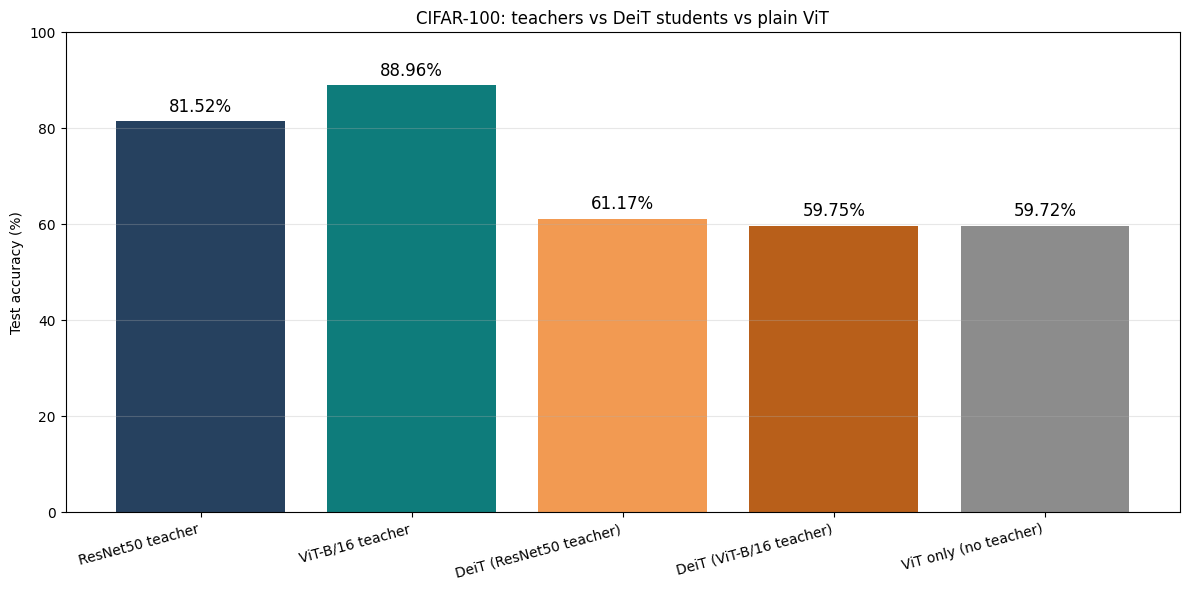

ResNet50 teacher              81.52%
ViT-B/16 teacher              88.96%
DeiT (ResNet50 teacher)       61.17%
DeiT (ViT-B/16 teacher)       59.75%
ViT only (no teacher)         59.72%


In [21]:
order = ['ResNet50 teacher', 'ViT-B/16 teacher', 'DeiT (ResNet50 teacher)', 'DeiT (ViT-B/16 teacher)', 'ViT only (no teacher)']
values = [results[k] for k in order]
colors = ['#26415F', '#0E7C7B', '#F29A52', '#B85F1A', '#8C8C8C']

fig, ax = plt.subplots(figsize=(12,6))
bars = ax.bar(order, values, color=colors)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=4, fontsize=12)
ax.set_ylim(0, 100)
ax.set_ylabel('Test accuracy (%)')
ax.set_title('CIFAR-100: teachers vs DeiT students vs plain ViT')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(f'{DATASET_PATH}/deit_results.png', dpi=200, bbox_inches='tight')
plt.show()

for k, v in zip(order, values):
  print(f"{k:28s} {v:6.2f}%")